In [1]:
from __future__ import annotations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# load dataet

In [2]:
def load_clean_dataset(path: Path):
    data = np.load(path, allow_pickle=True)

    states = data["states"]
    actions = data["actions"]
    rewards = data["rewards"]
    dones = data["dones"]
    feature_names = list(data["feature_names"])

    df = pd.DataFrame(states, columns=feature_names)

    df["action"] = actions
    df["reward"] = rewards
    df["done"] = dones

    return df, feature_names

In [3]:
# loading of clean dataset 
CLEAN_ROOT = Path("../../datasets/param_controller_cleaned")

train_df, FEATURE_COLS = load_clean_dataset(CLEAN_ROOT / "train_clean.npz")
val_df, _ = load_clean_dataset(CLEAN_ROOT / "val_clean.npz")

print("Feature count:", len(FEATURE_COLS))
print("Training transitions:", len(train_df))
print("Validation transitions:", len(val_df))

Feature count: 23
Training transitions: 148265
Validation transitions: 68997


In [4]:
# check 
display(train_df.head())
display(val_df.head())

,gvns_iter,improv_rate_W,avg_delta_W,PV,pen_ratio,k,stagnation_time_pressure,horizon,avg_tw_width,min_tw_width,...,waiting_time_ratio,improv_trend,delta_trend,param_shaking,param_acceptance,param_penalty,elapsed,action,reward,done
0,-0.4,-3.0,-1.719597,-1.0,0.000000,0.0,0.0,0.277108,-0.353076,-0.28,...,-0.779426,0.0,0.055803,-0.534698,-0.095391,-1.257423,-0.808862,6,0.200668,0
1,-0.4,2.0,4.620785,1.0,6.390488,0.0,0.0,0.277108,-0.353076,-0.28,...,0.226604,0.0,0.055803,-0.534698,-0.095391,-1.187493,-0.808847,0,0.183138,0
2,-0.4,2.0,4.423749,1.0,6.381904,0.0,0.0,0.277108,-0.353076,-0.28,...,0.231707,0.0,0.055803,-0.534698,-0.095391,-1.208472,-0.808827,2,0.176763,0
3,-0.4,2.0,4.290074,1.0,6.372890,0.0,0.0,0.277108,-0.353076,-0.28,...,0.231626,0.0,0.055803,-0.405626,-0.095391,-1.208472,-0.808802,6,0.159717,0
4,-0.4,2.0,4.084513,1.0,6.370000,0.0,0.0,0.277108,-0.353076,-0.28,...,0.224595,0.0,-0.368488,-0.405626,-0.095391,-1.135605,-0.808780,5,0.160699,0


,gvns_iter,improv_rate_W,avg_delta_W,PV,pen_ratio,k,stagnation_time_pressure,horizon,avg_tw_width,min_tw_width,...,waiting_time_ratio,improv_trend,delta_trend,param_shaking,param_acceptance,param_penalty,elapsed,action,reward,done
0,-0.4,-3.0,-1.719597,-1.0,0.000000,0.0,0.0,0.277108,0.368726,-0.24,...,-0.779426,0.0,0.055803,-0.534698,-0.095391,-1.257423,-0.808862,3,0.156344,0
1,-0.4,2.0,1.616116,1.0,5.693358,0.0,0.0,0.277108,0.368726,-0.24,...,0.133353,0.0,0.055803,-0.663771,-0.329690,-1.257423,-0.808860,0,0.158940,0
2,-0.4,2.0,1.795527,1.0,5.686720,0.0,0.0,0.277108,0.368726,-0.24,...,0.131361,0.0,0.055803,-0.625049,-0.259400,-1.257423,-0.808845,4,0.192383,0
3,-0.4,2.0,2.700000,1.0,5.660430,0.0,0.0,0.277108,0.368726,-0.24,...,0.124557,0.0,0.055803,-0.875062,-0.698475,-1.257423,-0.808836,6,0.155914,0
4,-0.4,2.0,2.510497,1.0,5.667675,0.0,0.0,0.277108,0.368726,-0.24,...,0.126866,0.0,1.125453,-0.875062,-0.698475,-1.187493,-0.808834,4,0.290105,0


# global sanity check

In [5]:
def basic_sanity_checks(df: pd.DataFrame, name: str):
    print(f"\n=== {name.upper()} SANITY CHECKS ===")

    # -------------------------
    # Feature presence
    # -------------------------
    missing_cols = [c for c in FEATURE_COLS if c not in df.columns]
    print("Missing feature columns:", missing_cols)

    # -------------------------
    # Numerical issues
    # -------------------------
    X = df[FEATURE_COLS].to_numpy(dtype=np.float64)

    print("NaNs in features:", int(np.isnan(X).sum()))
    print("Infs in features:", int(np.isinf(X).sum()))
    print("Reward NaNs:", int(df["reward"].isna().sum()))
    print("Action NaNs:", int(df["action"].isna().sum()))

    # -------------------------
    # Basic distributions
    # -------------------------
    print("Done ratio:", float(df["done"].mean()))

    print("\nReward stats:")
    display(df["reward"].describe())

    print("\nAction distribution:")
    display(df["action"].value_counts(normalize=True).sort_index())

    # -------------------------
    # Transition-level checks
    # -------------------------
    print("\nFeature std (quick check):")
    display(df[FEATURE_COLS].std().sort_values().head(10))

basic_sanity_checks(train_df, "training")
basic_sanity_checks(val_df, "validation")


=== TRAINING SANITY CHECKS ===
Missing feature columns: []
NaNs in features: 0
Infs in features: 0
Reward NaNs: 0
Action NaNs: 0
Done ratio: 0.0

Reward stats:


count    148265.000000
mean          0.073513
std           0.120979
min          -0.407063
25%          -0.050000
50%           0.067090
75%           0.158780
max           1.000000
Name: reward, dtype: float64


Action distribution:


action
0    0.125316
1    0.126179
2    0.124655
3    0.125734
4    0.122456
5    0.123616
6    0.125768
7    0.126274
Name: proportion, dtype: float64


Feature std (quick check):


PV                    0.443711
waiting_time_ratio    0.514342
gvns_iter             0.530918
elapsed               0.624429
late_tw_ratio         0.631468
param_penalty         0.633580
tw_tightness          0.646355
route_len_mean        0.714369
param_shaking         0.779250
param_acceptance      0.785782
dtype: float32

... (2 outputs left out)


Action distribution:


action
0    0.125165
1    0.124252
2    0.123802
3    0.125991
4    0.125948
5    0.124455
6    0.124658
7    0.125730
Name: proportion, dtype: float64


Feature std (quick check):


PV                    0.402439
waiting_time_ratio    0.443885
min_tw_width          0.587058
elapsed               0.603313
param_penalty         0.629726
param_shaking         0.782561
param_acceptance      0.792546
gvns_iter             0.804146
route_len_mean        0.868863
horizon               0.874345
dtype: float32

# Reward distribution

In [6]:
def reward_summary(df: pd.DataFrame):
    return pd.Series({
        "count": len(df),
        "mean": df["reward"].mean(),
        "std": df["reward"].std(),
        "min": df["reward"].min(),
        "p01": df["reward"].quantile(0.01),
        "p05": df["reward"].quantile(0.05),
        "median": df["reward"].median(),
        "p95": df["reward"].quantile(0.95),
        "p99": df["reward"].quantile(0.99),
        "max": df["reward"].max(),
    })

reward_split_summary = pd.DataFrame({
    "training": reward_summary(train_df),
    "validation": reward_summary(val_df),
}).T

display(reward_split_summary)

,count,mean,std,min,p01,p05,median,p95,p99,max
training,148265.0,0.073513,0.120979,-0.407063,-0.055122,-0.05,0.067090,0.232551,0.376739,1.0
validation,68997.0,0.064622,0.117970,-0.365795,-0.072951,-0.05,0.054097,0.222033,0.345069,1.0


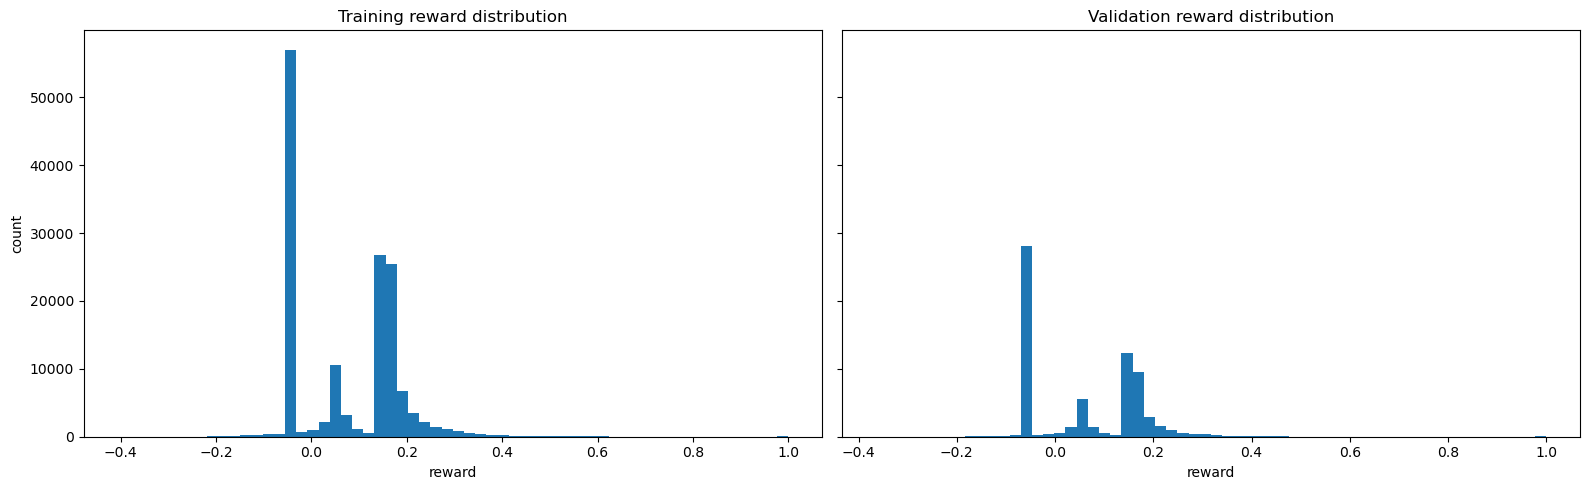

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
axes[0].hist(train_df["reward"], bins=60)
axes[0].set_title("Training reward distribution")
axes[0].set_xlabel("reward")
axes[0].set_ylabel("count")

axes[1].hist(val_df["reward"], bins=60)
axes[1].set_title("Validation reward distribution")
axes[1].set_xlabel("reward")

plt.tight_layout()
plt.show()

# Feature scale

In [8]:
def feature_summary(df: pd.DataFrame, feature_cols):
    rows = []
    for c in feature_cols:
        s = pd.to_numeric(df[c], errors="coerce")
        rows.append({
            "feature": c,
            "mean": s.mean(),
            "std": s.std(),
            "min": s.min(),
            "q01": s.quantile(0.01),
            "q05": s.quantile(0.05),
            "median": s.median(),
            "q95": s.quantile(0.95),
            "q99": s.quantile(0.99),
            "max": s.max(),
            "unique": s.nunique(dropna=True),
            "pct_zero": float((s == 0).mean()),
            "missing": int(s.isna().sum()),
        })
    out = pd.DataFrame(rows)
    out["abs_mean"] = out["mean"].abs()
    out["cv"] = out["std"] / (out["abs_mean"] + 1e-12)
    return out.sort_values("std", ascending=False)

train_feat_summary = feature_summary(train_df, FEATURE_COLS)
val_feat_summary = feature_summary(val_df, FEATURE_COLS)

display(train_feat_summary.head(15))
display(train_feat_summary.tail(15))

,feature,mean,std,min,q01,q05,median,q95,q99,max,unique,pct_zero,missing,abs_mean,cv
15,avg_lateness_norm,1.261748,3.405180,0.000000,0.000000,0.000000,0.0,6.496962,17.103248,52.781616,22473,0.557482,0,1.261748,2.698781
17,improv_trend,0.492376,2.990876,-3.000000,-2.249998,-1.500000,0.0,4.499985,11.999960,26.999777,134,0.344673,0,0.492376,6.074371
6,stagnation_time_pressure,1.119779,2.818914,0.000000,0.000000,0.000000,0.0,6.158464,15.397001,47.030170,54787,0.618710,0,1.119779,2.517384
4,pen_ratio,1.115258,2.458282,0.000000,0.000000,0.000000,0.0,6.381926,12.132460,21.593578,50439,0.552733,0,1.115258,2.204227
2,avg_delta_W,0.405458,2.020679,-1.719597,-1.364828,-1.059902,0.0,2.678879,11.625184,12.928397,115052,0.000013,0,0.405458,4.983695
18,delta_trend,0.412083,1.533065,-0.591464,-0.591415,-0.541217,0.0,2.250992,9.085816,25.857868,128685,0.000007,0,0.412083,3.720284
5,k,0.648636,1.253492,0.000000,0.000000,0.000000,0.0,4.000000,6.000000,7.000000,8,0.624996,0,0.648636,1.932505
14,route_len_max_ratio,0.313348,1.184282,-3.600001,-1.080000,-0.800000,0.0,2.800001,4.800000,7.600001,144,0.085401,0,0.313348,3.779443
13,route_len_std,0.399817,1.142104,-1.148061,-0.884677,-0.652557,0.0,3.435542,4.005488,5.281257,3649,0.001275,0,0.399817,2.856567
8,avg_tw_width,0.387006,1.060049,-0.458408,-0.458408,-0.387240,0.0,1.609081,4.260994,6.331100,56,0.021994,0,0.387006,2.739103


,feature,mean,std,min,q01,q05,median,q95,q99,max,unique,pct_zero,missing,abs_mean,cv
13,route_len_std,0.399817,1.142104,-1.148061,-0.884677,-0.652557,0.0,3.435542,4.005488,5.281257,3649,0.001275,0,0.399817,2.856567
8,avg_tw_width,0.387006,1.060049,-0.458408,-0.458408,-0.387240,0.0,1.609081,4.260994,6.331100,56,0.021994,0,0.387006,2.739103
7,horizon,0.124705,1.016432,-0.732932,-0.732932,-0.732932,0.0,2.439759,2.439759,2.439759,6,0.138812,0,0.124705,8.150674
1,improv_rate_W,0.105855,1.000490,-3.000000,-2.000000,-1.500000,0.0,2.000000,2.000000,2.000000,59,0.153529,0,0.105855,9.451514
9,min_tw_width,0.309893,0.841648,-0.460000,-0.460000,-0.460000,0.0,1.606667,3.740000,3.740000,27,0.027505,0,0.309893,2.715936
20,param_acceptance,0.070324,0.785782,-2.361663,-1.498732,-1.097128,0.0,1.466082,2.276862,5.055329,92290,0.000013,0,0.070324,11.173782
19,param_shaking,0.129401,0.779250,-1.968834,-1.278994,-0.939028,0.0,1.667172,2.333574,2.333574,106256,0.000013,0,0.129401,6.021985
12,route_len_mean,0.148129,0.714369,-1.875000,-1.041667,-0.721154,0.0,1.458333,2.410714,4.125000,29,0.102351,0,0.148129,4.822600
10,tw_tightness,-0.057513,0.646355,-1.094588,-1.088005,-0.936159,0.0,1.215077,1.378471,1.378471,55,0.030250,0,0.057513,11.238455
21,param_penalty,0.054847,0.633580,-1.257423,-1.081046,-0.896032,0.0,1.073580,1.073580,1.073580,34293,0.000027,0,0.054847,11.551693


In [9]:
ZERO_VAR_STD = 1e-8
NEAR_ZERO_VAR_STD = 1e-4

zero_var = train_feat_summary[train_feat_summary["std"].fillna(0) <= ZERO_VAR_STD]["feature"].tolist()
near_zero_var = train_feat_summary[train_feat_summary["std"].fillna(0) <= NEAR_ZERO_VAR_STD]["feature"].tolist()

print("Zero-variance features:", zero_var)
print("Near-zero-variance features:", near_zero_var)

Zero-variance features: []
Near-zero-variance features: []


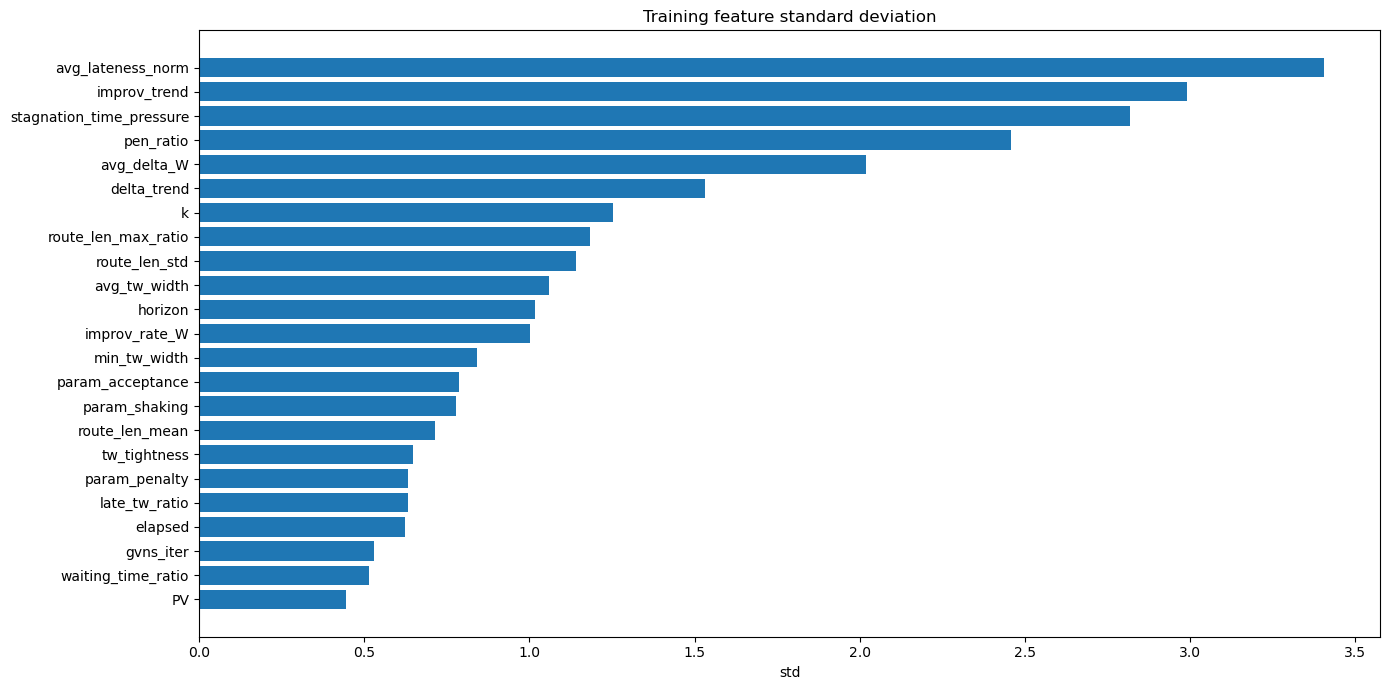

In [10]:
fig, ax = plt.subplots(figsize=(14, 7))
ordered = train_feat_summary.sort_values("std", ascending=True)
ax.barh(ordered["feature"], ordered["std"])
ax.set_title("Training feature standard deviation")
ax.set_xlabel("std")
plt.tight_layout()
plt.show()

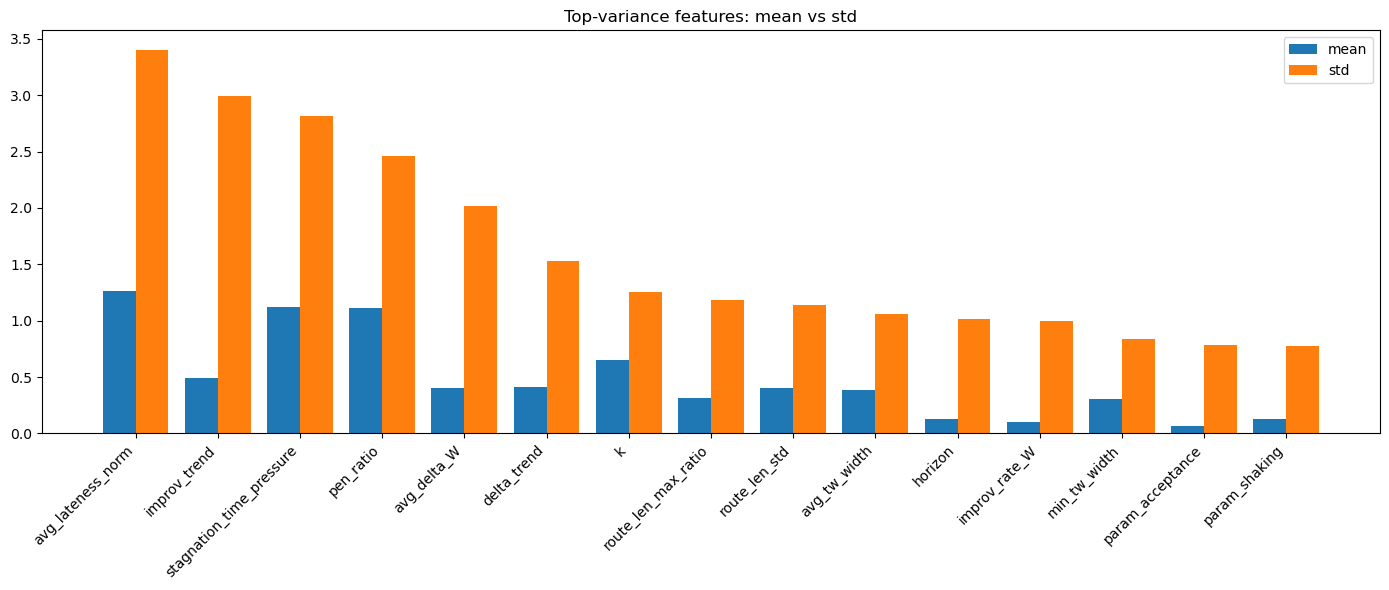

In [11]:
topn = 15
top_features = train_feat_summary.sort_values("std", ascending=False).head(topn)["feature"].tolist()
plot_df = train_feat_summary.set_index("feature").loc[top_features][["mean", "std"]]

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(plot_df))
ax.bar(x - 0.2, plot_df["mean"].values, width=0.4, label="mean")
ax.bar(x + 0.2, plot_df["std"].values, width=0.4, label="std")
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, rotation=45, ha="right")
ax.set_title("Top-variance features: mean vs std")
ax.legend()
plt.tight_layout()
plt.show()

# Feature correlations

In [12]:
train_corr = train_df[FEATURE_COLS].corr(method="pearson")

corr_pairs = []
for i, a in enumerate(FEATURE_COLS):
    for j, b in enumerate(FEATURE_COLS):
        if j <= i:
            continue
        val = float(train_corr.loc[a, b])
        corr_pairs.append((a, b, val, abs(val)))

corr_pairs_df = pd.DataFrame(corr_pairs, columns=["feature_a", "feature_b", "corr", "abs_corr"])
corr_pairs_df = corr_pairs_df.sort_values("abs_corr", ascending=False)

display(corr_pairs_df)

,feature_a,feature_b,corr,abs_corr
175,tw_tightness,late_tw_ratio,0.863274,0.863274
247,param_shaking,param_acceptance,0.844348,0.844348
100,k,stagnation_time_pressure,0.763139,0.763139
138,horizon,route_len_std,0.752809,0.752809
208,route_len_std,route_len_max_ratio,0.751073,0.751073
...,...,...,...,...
194,late_tw_ratio,param_shaking,-0.000624,0.000624
97,pen_ratio,param_acceptance,-0.000498,0.000498
240,improv_trend,param_acceptance,0.000205,0.000205
221,route_len_max_ratio,param_shaking,0.000148,0.000148


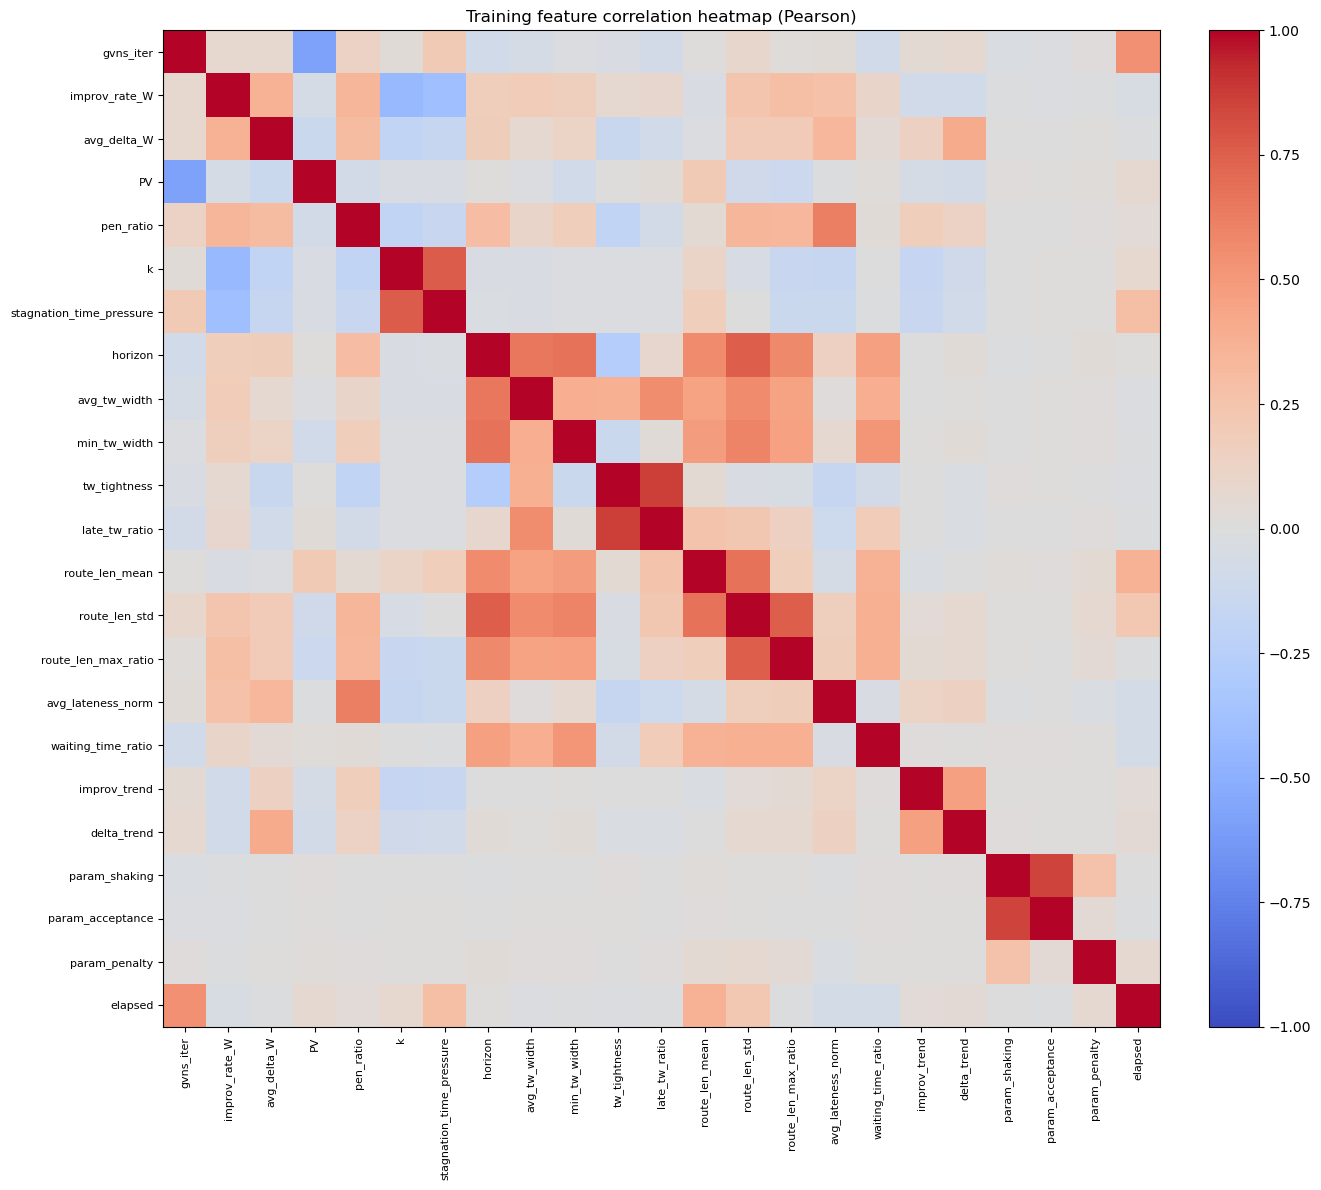

In [13]:
fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(train_corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(FEATURE_COLS)))
ax.set_yticks(np.arange(len(FEATURE_COLS)))
ax.set_xticklabels(FEATURE_COLS, rotation=90, fontsize=8)
ax.set_yticklabels(FEATURE_COLS, fontsize=8)
ax.set_title("Training feature correlation heatmap (Pearson)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [14]:
HIGH_CORR_THRESHOLD = 0.95
STRONG_CORR_THRESHOLD = 0.85

high_corr = corr_pairs_df[corr_pairs_df["abs_corr"] >= HIGH_CORR_THRESHOLD]
strong_corr = corr_pairs_df[corr_pairs_df["abs_corr"] >= STRONG_CORR_THRESHOLD]

print(f"Pairs with |corr| >= {HIGH_CORR_THRESHOLD}: {len(high_corr)}")
display(high_corr)

print(f"Pairs with |corr| >= {STRONG_CORR_THRESHOLD}: {len(strong_corr)}")
display(strong_corr.head(50))

Pairs with |corr| >= 0.95: 0


,feature_a,feature_b,corr,abs_corr


Pairs with |corr| >= 0.85: 1


,feature_a,feature_b,corr,abs_corr
175,tw_tightness,late_tw_ratio,0.863274,0.863274
